# Predicting My Reps from My Gym Logs

Almas Sapar

The code is available at [github.com/Almasx/cs156/tree/main/first-assignment](https://github.com/Almasx/cs156/tree/main/first-assignment).

I logged my gym sets for almost four years in three different apps (FitNotes in 2023 and 2024, then two others). Each row records the exercise, the weight and the number of repetitions (reps). A natural goal is to predict how many reps I will do with a given weight on the bar. However, the log can support this goal only in part. I choose the weight myself, and the log records no RPE and almost no failure marks, so it does not show how hard each set was. This study therefore measures how predictable my own sets are from my past training, compared with the natural variation between two consecutive sets at the same weight. If a model comes close to that level of variation, the remaining error likely comes mostly from day-to-day variation that the log does not record.

I kept the sets from 5 July 2026 onward as a final test set and did not test any model on them until all models were fixed.

The target is the number of reps in one working set. Every input to the model is known before the set starts. The inputs are the weight, the position of the set within the lift, the number of sets already done in the session, and the history of the lift in earlier sessions. I compare simple baselines with several machine learning models under three different ways to split the data.

In [1]:
import os, sys, subprocess, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupKFold, GridSearchCV, train_test_split
from sklearn.inspection import permutation_importance
import warnings
# sklearn/pandas FutureWarnings and convergence chatter would bury the outputs
warnings.filterwarnings('ignore')

SEED = 156
HOLDOUT_START = pd.Timestamp('2026-07-05')
MIN_REPS, MAX_REPS = 1, 30
EPLEY_DIVISOR = 30   # the 30 in Epley's e1RM = w * (1 + r / 30)
pd.set_option('display.width', 200)

# readable names for plots and the legend under the tables; the code keeps the short keys
NICE_NAMES = {'const_mean': 'predict the mean', 'repeat_last': 'repeat last session', 'inv_epley': 'inverse Epley',
              'linreg': 'linear regression', 'knn': 'kNN', 'tree': 'regression tree', 'rf': 'random forest',
              'hgb': 'gradient boosting'}


def clip_reps(pred):
    """Clip predictions to a possible rep count.

    Args:
        pred: predicted reps.

    Returns:
        array or Series, pred clipped to [MIN_REPS, MAX_REPS].
    """
    return np.clip(pred, MIN_REPS, MAX_REPS)

## Pipeline

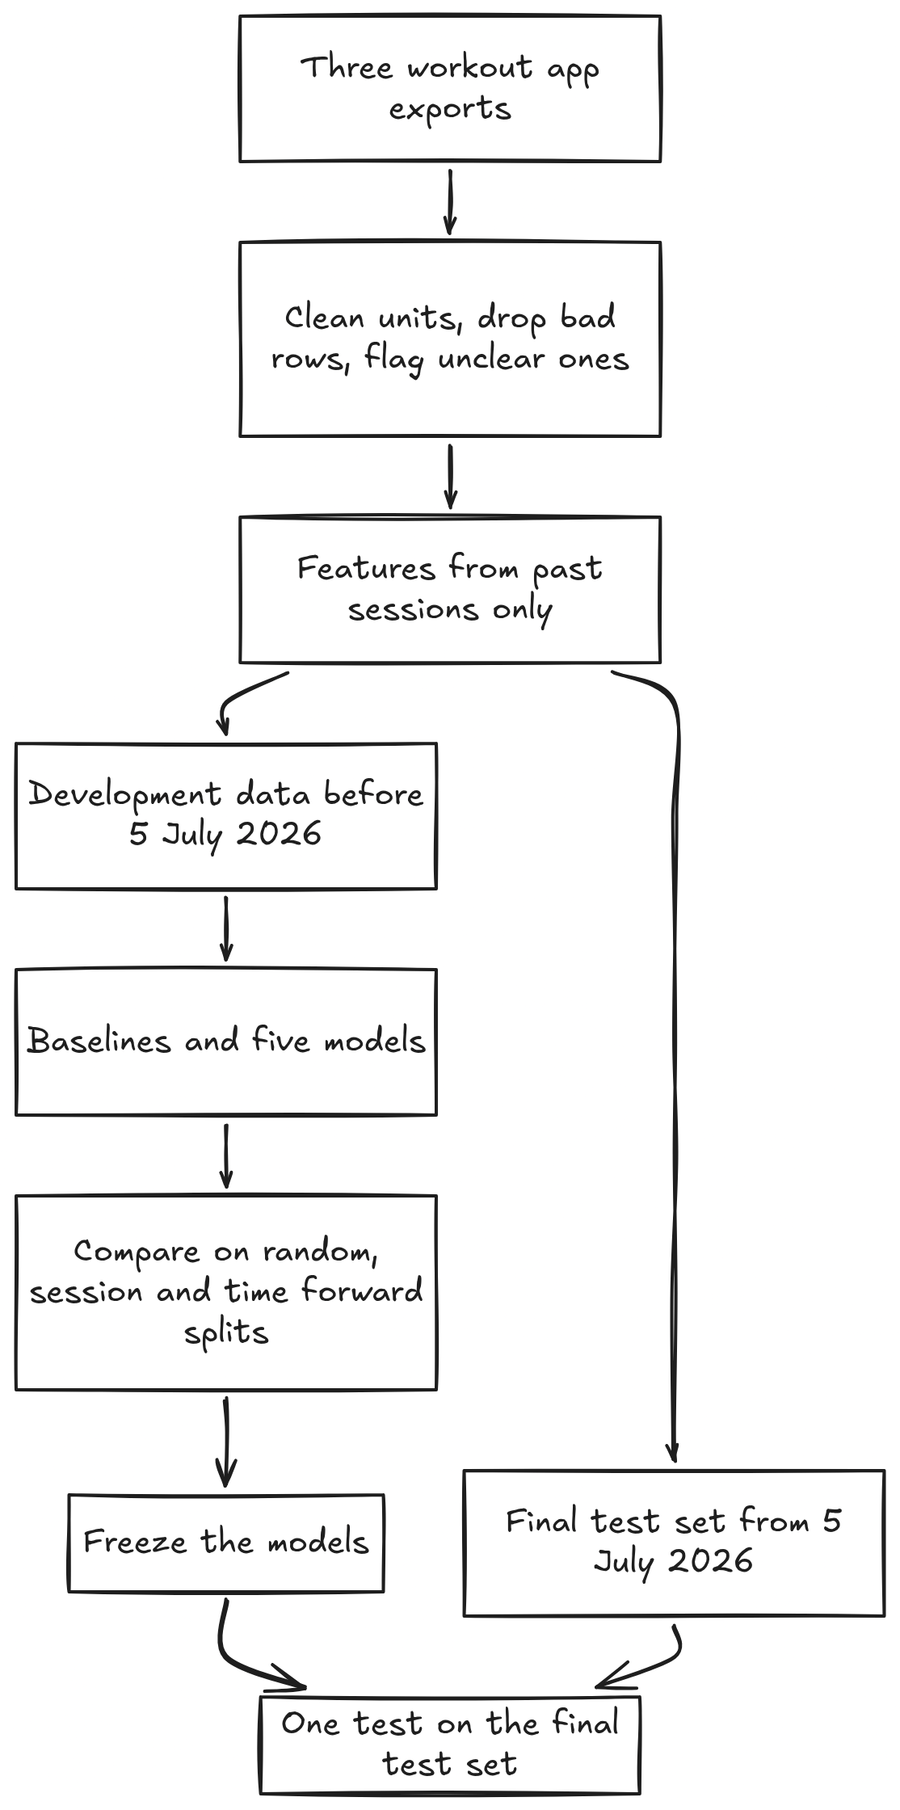

The main property of this design is that cleaning and features only look backward in time, and the last three months stay untouched until the final test.

## Data and Preprocessing

I have logged my workouts for almost four years, but I switched apps twice along the way, so my history is split across three exports with 9,686 rows. When I merged them, a lot of the numbers made no sense. The app I use now logs pounds, but some of my entries there were kilogram numbers that I typed into the pound field. The same app saved my rest timers as sets. FitNotes, my first app, put my bodyweight in the weight field for pull-ups and dips, and my second app did the same on a few sets.

I wrote `clean.py` to fix this with a fixed list of rules. It logs how many rows each rule removes and saves every dropped row with the reason, so I can check that nothing good was thrown away. For sets that looked like typos, I compared them only with other sets of the same lift in the same session or in earlier sessions, so the cleaning never uses a later session.

Some rows were harder. For dumbbell lifts I could not tell if a weight such as 24 kg, a typical value in my log, meant one dumbbell or both, which doubles or halves the load. For weighted pull-ups and dips the apps saved only the weight I added, not my full weight, so these sets do not compare well with other lifts. I did not want to guess, so I kept these 940 rows and flagged them. I also flagged 114 kilogram values that had no earlier history to check the unit against and 57 values whose unit I corrected. In total 1,093 rows carry at least one of these flags, because a few rows carry two. The appendix shows that leaving them out does not change the conclusions.

The table below groups the cleaning rules by the problem they fix, in the order they run. The code after it prints every rule with its row count.

| Problem I found | How I spotted it | What I did | Rows |
|---|---|---|---:|
| Rest timers saved as sets | Rows with no weight, no reps and only a rest length, after almost every set | Dropped | 2,162 |
| One workout logged in two apps | The same sets on the same day in two exports | Kept one copy | 1 |
| Test entries before I started using my current app | A few short sessions, months before real use | Dropped | 6 |
| Stretches, sprints and holds | A time or distance but no weight | Dropped | 255 |
| Bodyweight in the weight field | Pull-ups and dips whose weight was my bodyweight and not a plate load | Dropped, so my bodyweight stays out of the data | 381 |
| Marked warm-ups | The warm-up marker in two apps | Dropped | 6 |
| Missing or placeholder weights | Empty weights and values of 3 lb or less | Dropped | 213 |
| Kilograms in the pound field | A set at roughly 0.45 times the recent weight of the lift, which is what a kilogram number looks like in pounds | Converted to pounds | 57 changed |
| Typos | A set far heavier than any earlier session of the lift, far off the other sets that day, or more than 30 reps | Dropped | 4 |
| Sudden jumps in scale | A session top below 0.58 or above 1.7 times the median of the last five sessions of the lift | Dropped | 223 |
| Unclear load | Dumbbell pair or single unclear, added weight only, or a kilogram value with no history to check | Kept and flagged | 1,093 rows with at least one flag, including the 57 corrected sets |

Of the 6,435 kept rows, 6,048 are development rows (before 2026-07-05).

A logging typo shows up as a sudden jump compared with my recent sessions of that lift, so the jump rule compares the top weight of each session with the median top of my last five earlier sessions of that lift. The list `history` grows only after a session has been checked, so the rule looks only backward and cannot use later sessions or the final test set, as this excerpt from [clean.py](https://github.com/Almasx/cs156/blob/main/first-assignment/clean.py) shows.

```python
session_top = d.loc[idx, 'weight_lb'].max()
recent = [top for date, top in history if (today - date).days <= JUMP_WINDOW_DAYS][-HISTORY_SESSIONS:]
if len(recent) >= MIN_HISTORY_SESSIONS:
    ratio = session_top / np.median(recent)
    if ratio < JUMP_LOW or ratio > JUMP_HIGH:
        for i in idx:
            rule_of[i] = 'sudden_jump_vs_recent_sessions'
# the session still goes into history even if it gets dropped, so a real new level is accepted after a few sessions
history.append((today, session_top))
```

In [2]:
# rerun the frozen cleaning script from the raw exports in raw/
if os.path.exists('raw/src1.csv'):
    subprocess.run([sys.executable, 'clean.py'], capture_output=True, text=True, check=True)
RULE_NAMES = {
    'rest_timer_saved_as_set': 'Rest timers saved as sets',
    'same_workout_in_two_apps': 'Same workout in two apps',
    'test_entry_before_current_app': 'Test entries before using the app',
    'time_or_distance_only': 'Time or distance only (cardio, stretches, holds)',
    'bodyweight_in_weight_field': 'Bodyweight in weight field',
    'marked_warmup': 'Warm-ups',
    'missing_weight': 'Missing weight',
    'placeholder_weight': 'Placeholder weight',
    'missing_reps': 'Missing reps',
    'kg_export_converted_to_lb': 'Kilograms converted to pounds',
    'rounded_lb_value_fixed': 'Rounded pounds fixed',
    'kg_typed_in_lb_field': 'Kilograms typed as pounds',
    'typo_above_3x_earlier_max': 'Typo, far above earlier max',
    'typo_above_3x_session_median': "Typo, far above that day's other sets",
    'typo_below_quarter_session_top': "Typo, far below that day's top set",
    'more_than_30_reps': 'More than 30 reps',
    'sudden_jump_vs_recent_sessions': 'Sudden jump vs recent sessions',
    'flag_dumbbell_pair_or_single_unclear': 'Flag, dumbbell pair or single unclear',
    'flag_added_load_only': 'Flag, added load only',
    'flag_kg_not_checkable': 'Flag, kilograms not checkable',
    'flag_after_long_break': 'Flag, long break before',
    'flag_uncertain_exercise_name': 'Flag, uncertain exercise name',
}
rules = pd.read_csv('data/rule_table.csv')
print('raw rows', rules.rows_before.iloc[0], '| kept rows', rules.rows_after.iloc[-1])
rules = rules[rules.rule != 'raw_rows_loaded']
assert set(rules.rule) <= set(RULE_NAMES)
pd.DataFrame({'rule': rules.rule.map(RULE_NAMES).values, 'rows dropped': rules.dropped.values,
              'rows changed or flagged': rules.changed.values}, index=range(1, len(rules) + 1))

raw rows 9686 | kept rows 6435


,rule,rows dropped,rows changed or flagged
1,Rest timers saved as sets,2162,0
2,Same workout in two apps,1,0
3,Test entries before using the app,6,0
4,"Time or distance only (cardio, stretches, holds)",255,0
5,Bodyweight in weight field,381,0
6,Warm-ups,6,0
7,Missing weight,51,0
8,Placeholder weight,162,0
9,Missing reps,0,0
10,Kilograms converted to pounds,0,4426


In [3]:
def read_clean_sets():
    """Read the cleaned sets with session timestamp and row id.

    Returns:
        DataFrame, all cleaned sets, including the holdout rows.
    """
    sets = pd.read_csv('data/sets_clean.csv')
    sets['date'] = pd.to_datetime(sets['date'])
    sets['sess_ts'] = pd.to_datetime(sets.session_id.str.split('_', n=1).str[1], format='ISO8601')
    sets['row_id'] = np.arange(len(sets))
    return sets


def load_dev():
    """Load the cleaned sets before the holdout start.

    Returns:
        DataFrame, development rows only; holdout rows never leave this function.
    """
    sets = read_clean_sets()
    return sets[sets.date < HOLDOUT_START].copy()


dev = load_dev()
print(len(dev), 'dev rows,', dev.session_id.nunique(), 'sessions,', dev.exercise.nunique(), 'exercises,', dev.date.min().date(), 'to', dev.date.max().date())
print(dev.source.value_counts().to_dict())
print('drop sets:', (dev.set_type == 'drop').sum(), 'failure sets:', (dev.set_type == 'failure').sum())

6048 dev rows, 364 sessions, 102 exercises, 2023-01-14 to 2026-07-01
{'src1': 3086, 'src2': 1729, 'src3': 1233}
drop sets: 252 failure sets: 1


Sets from very different lifts have to be comparable, because 100 lb means something very different for curls and for squats, so most weights enter the model as log ratios to the history of the same lift, for example the weight of today divided by the best estimated 1RM so far. The history of a lift comes only from earlier sessions. The code aggregates each (session, lift) pair and applies `shift(1)` before any cumulative, rolling or expanding operation, so session $s$ never sees itself. Sessions are ordered by timestamp and not by file order, because one app writes the newest session first.

In [4]:
def epley_reps(weight, e1rm):
    """Inverse Epley rep estimate.

    Args:
        weight: weight on the bar in lb.
        e1rm: estimated one-rep max in lb.

    Returns:
        array or Series, reps clipped to 1 to 30.
    """
    return clip_reps(EPLEY_DIVISOR * (e1rm / weight - 1))


def add_session_order(sets):
    """Number sessions by timestamp and count earlier sets in each session.

    Args:
        sets: cleaned sets.

    Returns:
        DataFrame, sets with sess_num, days_since_any, n_earlier_sets_session, is_drop and e1rm.
    """
    sessions = sets.groupby('session_id').agg(sess_ts=('sess_ts', 'first'), date=('date', 'first')).reset_index()
    sessions = sessions.sort_values(['sess_ts', 'session_id']).reset_index(drop=True)
    sessions['sess_num'] = np.arange(len(sessions))
    sessions['days_since_any'] = sessions.date.diff().dt.days
    sets = sets.merge(sessions[['session_id', 'sess_num', 'days_since_any']], on='session_id')
    sets = sets.sort_values(['sess_num', 'row_id']).reset_index(drop=True)
    sets['n_earlier_sets_session'] = sets.groupby('sess_num').cumcount()
    sets['is_drop'] = (sets.set_type == 'drop').astype(int)
    sets['e1rm'] = sets.weight_lb * (1 + sets.reps / EPLEY_DIVISOR)
    return sets


def lift_history(sets):
    """Summarize earlier sessions of each lift, shifted so a session never sees itself.

    Args:
        sets: output of add_session_order.

    Returns:
        DataFrame, one row per (sess_num, exercise) with the history columns.
    """
    summary = dict(top_w=('weight_lb', 'max'), best_e1=('e1rm', 'max'), mean_reps=('reps', 'mean'), first_reps=('reps', 'first'))
    per_lift = sets.groupby(['sess_num', 'exercise']).agg(date=('date', 'first'), **summary).reset_index()
    per_lift_no_drops = sets[sets.is_drop == 0].groupby(['sess_num', 'exercise']).agg(**summary)
    per_lift = per_lift.set_index(['sess_num', 'exercise'])
    per_lift.update(per_lift_no_drops)
    per_lift = per_lift.reset_index().sort_values(['exercise', 'sess_num']).reset_index(drop=True)

    by_lift = per_lift.groupby('exercise')
    per_lift['best_prev'] = by_lift.best_e1.transform(lambda s: s.shift(1).cummax())
    per_lift['last3_e1'] = by_lift.best_e1.transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean())
    per_lift['last_top_w'] = by_lift.top_w.shift(1)
    per_lift['last_mean_reps'] = by_lift.mean_reps.shift(1)
    per_lift['last_first_reps'] = by_lift.first_reps.shift(1)
    per_lift['ex_hist_mean_reps'] = by_lift.mean_reps.transform(lambda s: s.shift(1).expanding().mean())
    per_lift['n_prev_sess'] = by_lift.cumcount()
    per_lift['days_since_ex'] = by_lift.date.diff().dt.days
    history_cols = ['best_prev', 'last3_e1', 'last_top_w', 'last_mean_reps', 'last_first_reps', 'ex_hist_mean_reps',
                    'n_prev_sess', 'days_since_ex']
    return per_lift[['sess_num', 'exercise'] + history_cols]


def add_ratio_features(sets):
    """Add log weight, log ratios to history, log day gaps and the Epley guess.

    Args:
        sets: sets merged with lift_history.

    Returns:
        DataFrame, the same frame with the ratio features and has_hist.
    """
    weight = sets.weight_lb
    sets['logw'] = np.log(weight)
    sets['log_rel_best'] = np.log(weight / sets.best_prev)
    sets['log_rel_last3'] = np.log(weight / sets.last3_e1)
    sets['log_rel_lastw'] = np.log(weight / sets.last_top_w)
    sets['log_days_ex'] = np.log1p(sets.days_since_ex)
    sets['log_days_any'] = np.log1p(sets.days_since_any.fillna(0))
    sets['log_nprev'] = np.log1p(sets.n_prev_sess)
    sets['epley_last3'] = epley_reps(weight, sets.last3_e1)
    sets['has_hist'] = sets.last_mean_reps.notna().astype(int)
    return sets


def build_features(df):
    """Build past-only features for every set.

    Args:
        df: cleaned sets in any row order.

    Returns:
        DataFrame, copy of df with the FEATS columns plus has_hist, sorted by session and row.
    """
    sets = add_session_order(df.copy())
    sets = sets.merge(lift_history(sets), on=['sess_num', 'exercise'], how='left')
    sets = sets.sort_values(['sess_num', 'row_id']).reset_index(drop=True)
    return add_ratio_features(sets)


FEATS = ['logw', 'set_idx', 'n_earlier_sets_session', 'log_rel_best', 'log_rel_last3', 'log_rel_lastw', 'last_mean_reps',
         'last_first_reps', 'ex_hist_mean_reps', 'log_days_ex', 'log_days_any', 'log_nprev', 'epley_last3']
feats = build_features(dev)
feats[['exercise', 'weight_lb', 'reps', 'set_idx', 'last_mean_reps', 'best_prev', 'epley_last3', 'days_since_ex']].dropna().head()

,exercise,weight_lb,reps,set_idx,last_mean_reps,best_prev,epley_last3,days_since_ex
15,Bench Press (Barbell),110.23,8,0,7.0,167.554667,15.601379,3.0
16,Bench Press (Barbell),132.28,6,1,7.0,167.554667,8.000000,3.0
17,Bench Press (Barbell),132.28,6,2,7.0,167.554667,8.000000,3.0
18,Bench Press (Barbell),121.25,6,3,7.0,167.554667,11.456825,3.0
19,Bench Press (Barbell),132.28,4,4,7.0,167.554667,8.000000,3.0


My features use only what I know before a set starts, because that is all I know in the gym. They are today's weight, the position of the set, the sets already done in the session and the history of the lift in earlier sessions. If a feature accidentally used later sets, the models would look better than they really are. To make sure this did not happen, I checked the features in four ways. Shuffling the input rows did not change any of them, and a separate simple loop that recomputes the mean reps of the last session for 200 random sets gave the same values. Then, for 20 different starting sessions, I replaced the reps and weights of that session and of every later one with random numbers and checked that no feature of an earlier session changed, and none did. I also built a deliberately leaky feature, a running mean of reps that includes the current set, and this check caught it, so I know the check works.

In [5]:
# leakage test 1: shuffling the input rows must give the same features
rng = np.random.default_rng(SEED)
LEAK_CHECK_COLS = FEATS + ['best_prev', 'last3_e1', 'sess_num']


def feats_by_row(table):
    """Index the leakage-check columns by row_id.

    Args:
        table: output of build_features.

    Returns:
        DataFrame, LEAK_CHECK_COLS indexed and sorted by row_id.
    """
    return table.set_index('row_id')[LEAK_CHECK_COLS].sort_index()


base = feats_by_row(feats)
feats_shuffled = build_features(dev.sample(frac=1, random_state=1))
print('1) shuffled input -> same features:', np.allclose(base.values, feats_by_row(feats_shuffled).values, equal_nan=True))

1) shuffled input -> same features: True


In [6]:
# leakage test 2: recompute last session's mean reps by hand for 200 random rows
sample_rows = feats[feats.has_hist == 1].sample(200, random_state=2)
mismatches = 0
for _, row in sample_rows.iterrows():
    earlier = feats[(feats.exercise == row.exercise) & (feats.sess_num < row.sess_num)]
    last_session = earlier[earlier.sess_num == earlier.sess_num.max()]
    if (last_session.is_drop == 0).any():
        last_session = last_session[last_session.is_drop == 0]
    if not np.isclose(last_session.reps.mean(), row.last_mean_reps):
        mismatches += 1
print('2) brute force mismatches in 200 rows:', mismatches)

2) brute force mismatches in 200 rows: 0


In [7]:
# leakage test 3 (poison): junk reps and weights from session k on must not change any earlier feature.
# in session k itself only features built from the set's own weight may move
session_of_row = feats.set_index('row_id').sess_num
HISTORY_ONLY_COLS = ['last_mean_reps', 'last_first_reps', 'ex_hist_mean_reps', 'best_prev', 'last3_e1', 'log_nprev',
                     'log_days_ex', 'set_idx', 'n_earlier_sets_session']


def poison(k):
    """Rebuild features after replacing reps and weights from session k on with random values.

    Args:
        k: first poisoned session number.

    Returns:
        DataFrame, features built from the poisoned copy of dev.
    """
    poisoned_sets = dev.copy()
    later = poisoned_sets.row_id.map(session_of_row) >= k
    poisoned_sets.loc[later, 'reps'] = rng.integers(1, 30, later.sum())
    poisoned_sets.loc[later, 'weight_lb'] = poisoned_sets.loc[later, 'weight_lb'] * rng.uniform(0.3, 3, later.sum())
    return build_features(poisoned_sets)


sessions_changed = 0
poison_points = rng.choice(np.arange(30, feats.sess_num.max()), 20, replace=False)
for k in poison_points:
    poisoned = poison(k)
    clean_f, poisoned_f = feats_by_row(feats), feats_by_row(poisoned)
    before_k = clean_f.sess_num < k
    at_k = clean_f.sess_num == k
    n_bad = (~np.isclose(clean_f[before_k].values, poisoned_f[before_k].values, equal_nan=True)).sum()
    n_bad += (~np.isclose(clean_f.loc[at_k, HISTORY_ONLY_COLS].values, poisoned_f.loc[at_k, HISTORY_ONLY_COLS].values, equal_nan=True)).sum()
    sessions_changed += n_bad > 0
print('3) poison test: sessions where past features changed:', sessions_changed, 'of', len(poison_points))

3) poison test: sessions where past features changed: 0 of 20


In [8]:
# leakage test 4 (negative control): a feature WITHOUT the shift has to fail the poison test
def leaky(table):
    """Deliberately leaky running mean of reps per lift (no shift), the negative control.

    Args:
        table: output of build_features.

    Returns:
        Series, expanding mean of reps that includes the current set.
    """
    table = table.sort_values(['sess_num', 'row_id'])
    return table.groupby('exercise').reps.transform(lambda s: s.expanding().mean())


k = int(poison_points[0])
poisoned = poison(k)
leaky_clean = feats.assign(l=leaky(feats)).set_index('row_id').l.sort_index()
leaky_poisoned = poisoned.assign(l=leaky(poisoned)).set_index('row_id').l.sort_index()
up_to_k = (session_of_row.sort_index() <= k).values
print('4) negative control (no shift): rows changed at sessions <= k:', int((~np.isclose(leaky_clean[up_to_k], leaky_poisoned[up_to_k])).sum()), '(should be > 0)')

4) negative control (no shift): rows changed at sessions <= k: 19 (should be > 0)


## Baselines and Models

A model is only useful if it beats rules that need no learning, so I start with two simple baselines. The first one always predicts the average number of reps. The second one, which I call repeating the last session, predicts the mean reps of my last session on that lift. Lifters already estimate reps with formulas, so I also test a classic one. Epley (1985) estimates a one-repetition maximum $e$ from a set of $r$ reps at weight $w$. If I invert the formula, I get a rep estimate from a 1RM estimate $\hat e$. For $\hat e$ I use the mean of the best e1RM over the last 3 sessions of the lift, and I clip the result to the range from 1 to 30.
$$e = w\left(1+\frac{r}{30}\right), \qquad \hat r = \text{clip}\left(30\left(\frac{\hat e}{w}-1\right),\,1,\,30\right)$$
The cell below prints a real example from my log. On 2025-09-06 I did a bench press set at 176.37 lb, and the last-3 e1RM was 215.32 lb. The formula gives $\hat r = 30(215.32/176.37-1) = 6.62$, but I actually did 4 reps. The formula describes a single fresh set taken to failure. In my log, however, reps fall from the early to the later sets of an exercise at a similar weight, and the 1RM estimate that the formula divides by is itself noisy. These are likely reasons for the gap, but the notebook does not test them separately.

In [9]:
# Epley on one real bench set
bench = feats[(feats.exercise == 'Bench Press (Barbell)') & feats.last3_e1.notna() & (feats.is_drop == 0) & (feats.date >= '2025-09-01')].iloc[0]
print(bench.date.date(), bench.weight_lb, 'lb, did', bench.reps, 'reps | last-3 e1RM %.2f' % bench.last3_e1)
print('inverse Epley: %d * (%.2f / %.2f - 1) = %.2f' % (EPLEY_DIVISOR, bench.last3_e1, bench.weight_lb, EPLEY_DIVISOR * (bench.last3_e1 / bench.weight_lb - 1)))

2025-09-06 176.37 lb, did 4 reps | last-3 e1RM 215.32
inverse Epley: 30 * (215.32 / 176.37 - 1) = 6.62


In [10]:
model_rows = feats[feats.has_hist == 1].reset_index(drop=True)
print(len(model_rows), 'modelable rows (lift done at least once before),', len(feats) - len(model_rows), 'cold start rows dropped,', model_rows.session_id.nunique(), 'sessions')
print('reps: mean %.2f median %d sd %.2f, share 8-12: %.3f' % (model_rows.reps.mean(), model_rows.reps.median(), model_rows.reps.std(), model_rows.reps.between(8, 12).mean()))

5756 modelable rows (lift done at least once before), 292 cold start rows dropped, 361 sessions
reps: mean 10.23 median 10 sd 3.37, share 8-12: 0.622


I start the learned models with linear regression, because it is the simplest one and shows how far a straight line in the features gets me. It solves $\min_\beta \|y-X\beta\|^2$ and has the closed form $\beta=(X^TX)^{-1}X^Ty$. However, the relation between weight, history and reps is probably not linear.

I use kNN because my training repeats a lot. I often do the same lift at a similar weight, so the sets that look most like a new one should give a good guess. kNN standardizes the features, so that pounds do not dominate the set index, then finds the $k$ closest training sets and averages their reps.
$$\hat y(x) = \frac{1}{k}\sum_{i\in N_k(x)} y_i, \qquad \text{dist}(x,x_i)=\|z(x)-z(x_i)\|_2$$
If similar situations end in similar reps, the neighbors should win. If kNN loses, my past is a weaker guide than it seems.

A regression tree tests a different idea, that reps might drop at certain points, for example once the weight gets close to my best. At each node it picks the feature $j$ and the cut $t$ that leave the lowest squared error, and each leaf predicts the mean reps of its rows.
$$\min_{j,t}\; \sum_{i: x_{ij}\le t}(y_i-\bar y_L)^2 + \sum_{i: x_{ij}>t}(y_i-\bar y_R)^2$$
Here $x_{ij}$ is the value of feature $j$ for set $i$, for example the weight or the set position, $t$ is the cutoff, and $\bar y_L$ and $\bar y_R$ are the average reps of the sets on each side of the cutoff. Because my second set at the same weight has about 2 reps fewer than the first and my third about 3 fewer, a split on the set position that puts first sets on one side and later sets on the other lets each side predict its own mean reps. Each side's mean is then closer to the reps of the sets it covers, so the squared error falls compared with one mean for all sets. A tree that wins points to a few clear cut points, and a tree that loses suggests that reps change gradually. kNN and the tree are mainly here for comparison.

I care most about the ensembles. One tree can change a lot when a few rows move, and my log is noisy, so a random forest averages many trees grown on resampled rows. It grows $B$ deep trees $T_b$, each on its own bootstrap sample, and each split considers only a random half of the features.
$$\hat f(x) = \frac{1}{B}\sum_{b=1}^{B} T_b(x)$$
A cut point that many of these trees find is more likely to be real. If the forest clearly beats the single tree, much of what the tree found was noise.

Gradient boosting builds the prediction in small steps. Each new tree fits what the earlier ones still got wrong, so it can pick up small effects that the forest averages away. It starts from the mean $F_0$, and each new shallow tree $h_m$ is fit to the residuals $r_i = y_i - F_{m-1}(x_i)$. The learning rate $\nu$ (0.05 here) keeps each step small.
$$F_m(x) = F_{m-1}(x) + \nu\, h_m(x)$$
The residual $r_i$ is the number of reps I actually did in set $i$ minus what the model has guessed so far, so a positive residual means that the model still predicts too few reps. Each $h_m$ is a small tree fit to these misses, and its output is the correction that the model would like to make. My log is noisy, so some of these trees partly fit random misses, and for this reason $\nu$ adds only a small part of each correction so that no single noisy tree takes over the prediction. If boosting beats the forest, these small corrections matter. If the two tie, the log holds little structure beyond what the forest already finds. Both ensembles can also capture interactions such as "heavy relative to my best and also the third set", which linear regression cannot. If these flexible models win only on random splits, my patterns drift more than they repeat.
I tune $k$ (5 to 60) and the depth and leaf size of the tree inside each training fold with GroupKFold(3). The forest and boosting use fixed, conservative settings (minimum leaf 10 and 30, depth 3 for boosting), so that tuning does not favor them over the simpler models.

The test error should match how I would use a model, which is to predict my next sets from my past. A random 80/20 split by rows is the usual default, but sets from one session are not independent, so I also hold out whole sessions with GroupKFold (5 folds). Neither split predicts the future from the past, so the main split is a rolling origin with 6 test windows of half a year from 2023-07. Each window is trained on all data before it.

I want an error that I can read directly in reps. MAE gives this, and a miss of 2 reps counts twice as much as a miss of 1 rep. RMSE would count it four times, so a few sets that look like typos would dominate it. In the gym, a prediction of 9 when I do 10 is practically correct, so I also report the share of sets that the model predicts within one rep. All predictions are clipped to the range from 1 to 30, and they are rounded for the within-1 rate, because a set cannot have 8.4 reps.
$$\text{MAE} = \frac{1}{n}\sum_i |y_i-\hat y_i|, \qquad \text{within-1} = \frac{1}{n}\sum_i \mathbb{1}\big[\,|\text{round}(\text{clip}(\hat y_i,1,30)) - y_i| \le 1\,\big]$$

A difference between two models only matters if it is larger than the noise between my sessions, so I put a confidence interval on every comparison. For models A and B on the same rows, I compute $d_i = |y_i-\hat y^A_i| - |y_i-\hat y^B_i|$. Put simply, $d_i$ is how many more reps model A missed set $i$ by than model B, so it is negative when model A came closer to what I actually did. I resample whole sessions with replacement 2000 times, compute the mean $\bar d^*$ each time, and use the 2.5th and 97.5th percentiles. Each $\bar d^*$ is the average of $d_i$ over one resampled set of whole sessions, so the 2000 values show how much the comparison would change with a different mix of my sessions. These two percentiles bound the middle 95% of the resampled means, and if the whole interval is below zero, model A is reliably better on sessions like mine. I resample whole sessions and not single sets because the sets of one session come from the same day and are likely to miss together, so treating them as independent would make the intervals too narrow. A negative value means that model A is better.

In [11]:
KNN_GRID = {'kneighborsregressor__n_neighbors': [5, 15, 30, 60]}
TREE_GRID = {'decisiontreeregressor__max_depth': [3, 5, 8, 12], 'decisiontreeregressor__min_samples_leaf': [10, 30]}
HGB_SETTINGS = dict(max_depth=3, learning_rate=0.05, max_iter=150, min_samples_leaf=30, random_state=SEED)
ROLLING_STARTS = ['2023-07-01', '2024-01-01', '2024-07-01', '2025-01-01', '2025-07-01', '2026-01-01']
FOLD_MONTHS = 6


def within1(y, pred):
    """Mark predictions within one rep of the truth after clipping and rounding.

    Args:
        y: true reps.
        pred: predicted reps.

    Returns:
        array of float, 1.0 where the rounded prediction is within one rep, else 0.0.
    """
    return (np.abs(np.round(clip_reps(pred)) - y) <= 1).astype(float)


def median_imputer():
    """Median imputer for missing history features.

    Returns:
        SimpleImputer, unfitted imputer with strategy median.
    """
    return SimpleImputer(strategy='median')


def models():
    """Create fresh, unfitted models keyed by short name.

    Returns:
        dict, name to estimator. kNN and the tree are tuned with GroupKFold(3) by session when fitted.
    """
    return {
        'const_mean': DummyRegressor(),
        'linreg': make_pipeline(median_imputer(), LinearRegression()),
        'knn': GridSearchCV(make_pipeline(median_imputer(), StandardScaler(), KNeighborsRegressor()),
                            KNN_GRID, cv=GroupKFold(3), scoring='neg_mean_absolute_error'),
        'tree': GridSearchCV(make_pipeline(median_imputer(), DecisionTreeRegressor(random_state=SEED)),
                             TREE_GRID, cv=GroupKFold(3), scoring='neg_mean_absolute_error'),
        'rf': make_pipeline(median_imputer(), RandomForestRegressor(n_estimators=200, min_samples_leaf=10, max_features=0.5,
                                                                    random_state=SEED, n_jobs=-1)),
        'hgb': HistGradientBoostingRegressor(**HGB_SETTINGS),
    }


def splits(df, kind):
    """Yield train and test indices for one split scheme.

    Args:
        df: model rows.
        kind: 'random 80/20', 'group5 (session)' or 'rolling (6 folds)'.

    Yields:
        (int, array, array), fold number, train indices and test indices.
    """
    if kind == 'random 80/20':
        train_idx, test_idx = train_test_split(np.arange(len(df)), test_size=0.2, random_state=SEED)
        yield 0, train_idx, test_idx
    elif kind == 'group5 (session)':
        for fold, (train_idx, test_idx) in enumerate(GroupKFold(5).split(df, groups=df.session_id)):
            yield fold, train_idx, test_idx
    elif kind == 'rolling (6 folds)':
        for fold, start in enumerate(ROLLING_STARTS):
            start = pd.Timestamp(start)
            end = min(start + pd.DateOffset(months=FOLD_MONTHS), HOLDOUT_START)
            train_idx = np.where(df.date < start)[0]
            test_idx = np.where((df.date >= start) & (df.date < end))[0]
            yield fold, train_idx, test_idx


def run(df, kind, feature_cols=FEATS, which=None):
    """Fit every model on each fold of one split and collect test predictions.

    Args:
        df: model rows.
        kind: split name from SPLITS.
        feature_cols: feature columns.
        which: models to fit, None means all.

    Returns:
        DataFrame, one row per test set with reps, fold and clipped predictions, including repeat_last and inv_epley.
    """
    fold_preds = []
    for fold, train_idx, test_idx in splits(df, kind):
        X_train, X_test = df.iloc[train_idx][feature_cols], df.iloc[test_idx][feature_cols]
        y_train = df.reps.iloc[train_idx]
        pred = df.iloc[test_idx][['row_id', 'session_id', 'date', 'exercise', 'reps', 'is_drop', 'set_idx']].copy()
        pred['fold'] = fold
        pred['repeat_last'] = df.last_mean_reps.iloc[test_idx].values
        pred['inv_epley'] = df.epley_last3.iloc[test_idx].fillna(df.last_mean_reps.iloc[test_idx]).values
        for name, model in models().items():
            if which and name not in which:
                continue
            if isinstance(model, GridSearchCV):
                model.fit(X_train, y_train, groups=df.session_id.iloc[train_idx])
                pred[name + '_param'] = str(model.best_params_)   # only printed below
            else:
                model.fit(X_train, y_train)
            pred[name] = model.predict(X_test)
        fold_preds.append(pred)
    preds = pd.concat(fold_preds, ignore_index=True)
    for col in ['repeat_last', 'inv_epley'] + [name for name in models() if name in preds]:
        preds[col] = clip_reps(preds[col])
    return preds


SPLITS = ['random 80/20', 'group5 (session)', 'rolling (6 folds)']
MODELS = ['const_mean', 'repeat_last', 'inv_epley', 'linreg', 'knn', 'tree', 'rf', 'hgb']
preds_by_split = {split: run(model_rows, split) for split in SPLITS}
for split in SPLITS:
    print(split, len(preds_by_split[split]), 'test rows')
print(preds_by_split['rolling (6 folds)'].groupby('fold')[['knn_param', 'tree_param']].first())

# the same six rolling folds are reused for the learning curve, importance and recency check
ROLLING_FOLDS = list(splits(model_rows, 'rolling (6 folds)'))

random 80/20 1152 test rows
group5 (session) 5756 test rows
rolling (6 folds) 4449 test rows
                                     knn_param                                         tree_param
fold                                                                                             
0     {'kneighborsregressor__n_neighbors': 30}  {'decisiontreeregressor__max_depth': 5, 'decis...
1     {'kneighborsregressor__n_neighbors': 15}  {'decisiontreeregressor__max_depth': 5, 'decis...
2     {'kneighborsregressor__n_neighbors': 15}  {'decisiontreeregressor__max_depth': 12, 'deci...
3     {'kneighborsregressor__n_neighbors': 15}  {'decisiontreeregressor__max_depth': 12, 'deci...
4     {'kneighborsregressor__n_neighbors': 30}  {'decisiontreeregressor__max_depth': 12, 'deci...
5     {'kneighborsregressor__n_neighbors': 15}  {'decisiontreeregressor__max_depth': 5, 'decis...


## Results

### How Close a Prediction Can Get

A model cannot be judged without knowing how much my sets vary on their own, so I measure this in my own log. Two consecutive sets of the same lift at the same weight still differ by 1.56 reps on average after the typical drop is removed, and at the same weight my second set has about 2 reps fewer than the first and my third about 3 fewer. The code for both comes near the end of this section, because it reuses the features built for the models. An error of about that size is roughly the best I can expect from this log.

### Model Comparison

The first test for my training log is whether any learned model beats the baselines when it predicts the future from the past. The code below computes every comparison and prints the time-forward rows for four models. The printed outputs use short code names, and Table 1 gives the plain names.

In [12]:
N_BOOT = 2000


def boot(preds, a, b, kind='mae', n_boot=N_BOOT):
    """Paired session bootstrap of model a minus model b.

    Args:
        preds: predictions with reps and session_id.
        a: first prediction column.
        b: second prediction column, subtracted from a.
        kind: 'mae' for absolute errors, anything else for within-1 hits.
        n_boot: number of session resamples.

    Returns:
        tuple of float, mean difference, 2.5th percentile and 97.5th percentile.
    """
    y = preds.reps.values
    if kind == 'mae':
        diff = np.abs(preds[a].values - y) - np.abs(preds[b].values - y)
    else:
        diff = within1(y, preds[a].values) - within1(y, preds[b].values)
    session_codes, sessions = pd.factorize(preds.session_id)
    diff_sum_per_session = np.bincount(session_codes, weights=diff)
    sets_per_session = np.bincount(session_codes).astype(float)
    resampled = np.random.default_rng(SEED).integers(0, len(sessions), (n_boot, len(sessions)))
    # mean over all sets in the resampled sessions = sum of diffs / number of sets
    boot_means = diff_sum_per_session[resampled].sum(1) / sets_per_session[resampled].sum(1)
    return diff.mean(), np.percentile(boot_means, 2.5), np.percentile(boot_means, 97.5)


def fmt_ci(mean_diff, lo, hi, digits):
    """Format a difference and its interval as text.

    Args:
        mean_diff: mean difference.
        lo: lower interval end.
        hi: upper interval end.
        digits: decimals to show.

    Returns:
        str, text like "+0.12 [+0.05, +0.20]".
    """
    return f'{mean_diff:+.{digits}f} [{lo:+.{digits}f}, {hi:+.{digits}f}]'


rows = []
for split in SPLITS:
    preds = preds_by_split[split]
    for name in MODELS:
        row = {'split': split, 'model': name, 'MAE': np.abs(preds[name] - preds.reps).mean(),
               'within1': within1(preds.reps.values, preds[name].values).mean()}
        for ref in ['const_mean', 'repeat_last']:
            if name != ref:
                row['MAE diff vs ' + ref + ' [95% CI]'] = fmt_ci(*boot(preds, name, ref), 2)
                row['within-1 diff vs ' + ref + ' [95% CI]'] = fmt_ci(*boot(preds, name, ref, 'within1'), 3)
        rows.append(row)
table = pd.DataFrame(rows).fillna('-')
table['MAE'] = table.MAE.round(3)
table['within1'] = table.within1.round(3)
table.to_csv('data/results_dev.csv', index=False)
headline = table[(table.split == 'rolling (6 folds)') & table.model.isin(['const_mean', 'repeat_last', 'linreg', 'hgb'])]
headline.drop(columns='split').set_index('model')

,MAE,within1,MAE diff vs repeat_last [95% CI],within-1 diff vs repeat_last [95% CI],MAE diff vs const_mean [95% CI],within-1 diff vs const_mean [95% CI]
model,,,,,,
const_mean,2.760,0.352,"+0.47 [+0.39, +0.56]","-0.070 [-0.090, -0.048]",-,-
repeat_last,2.288,0.421,-,-,"-0.47 [-0.56, -0.39]","+0.070 [+0.048, +0.090]"
linreg,1.921,0.495,"-0.37 [-0.42, -0.32]","+0.073 [+0.057, +0.091]","-0.84 [-0.92, -0.76]","+0.143 [+0.122, +0.164]"
hgb,1.888,0.509,"-0.40 [-0.46, -0.35]","+0.087 [+0.070, +0.106]","-0.87 [-0.94, -0.80]","+0.157 [+0.138, +0.176]"


Table 1. Development error of all eight models on the time-forward split, with 4,449 test rows from 2023-07 onward.

| Model | MAE | Within-1 |
|:--|--:|--:|
| Mean | 2.760 | 0.352 |
| Repeat last session | 2.288 | 0.421 |
| Inverse Epley | 5.719 | 0.212 |
| Linear regression | 1.921 | 0.495 |
| kNN | 2.017 | 0.487 |
| Regression tree | 2.014 | 0.480 |
| Random forest | 1.876 | 0.518 |
| Gradient boosting | 1.888 | 0.509 |

The key comparison is gradient boosting against repeating the last session, and its MAE difference of -0.40 [-0.46, -0.35] stays clear of zero. Repeating the last session in turn beats the mean, with -0.47 [-0.56, -0.39]. The random forest and gradient boosting are practically equal, linear regression is close behind, kNN and the tree trail it, and inverse Epley is worse than the mean. The figure below shows all three splits side by side.

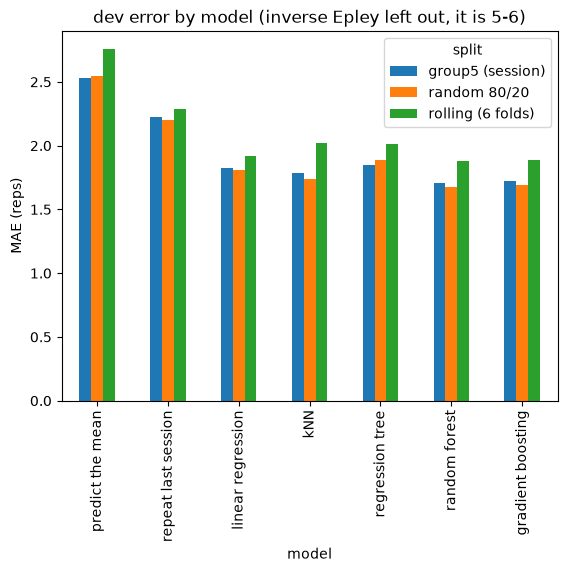

split        group5 (session)  random 80/20  rolling (6 folds)
model                                                         
const_mean              2.533         2.546              2.760
repeat_last             2.224         2.199              2.288
inv_epley               5.298         5.221              5.719
linreg                  1.824         1.807              1.921
knn                     1.784         1.741              2.017
tree                    1.849         1.889              2.014
rf                      1.707         1.673              1.876
hgb                     1.725         1.689              1.888


In [13]:
mae = table.pivot(index='model', columns='split', values='MAE').loc[MODELS]
mae.drop('inv_epley').rename(index=NICE_NAMES).plot.bar()
plt.ylabel('MAE (reps)')
plt.title('dev error by model (inverse Epley left out, it is 5-6)')
plt.show()
print(mae)

The split matters because I want to know how the models do on sessions they have not seen, in the order I lived them. Every learned model beats both baselines on every split. The random and the grouped split give almost the same errors, so sets from the same session do not leak information that would inflate the random split. The time-forward split is harder for every learned model. The rolling folds below show this window by window, and the comparison on identical rows after them measures the size of the loss.

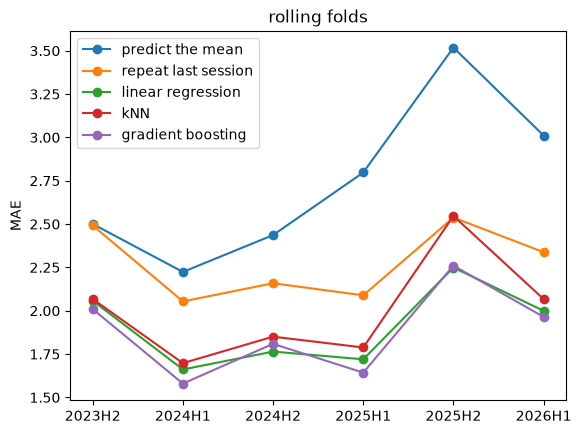

        const_mean  repeat_last  linreg    knn    hgb
2023H2       2.501        2.492   2.058  2.068  2.009
2024H1       2.224        2.054   1.661  1.698  1.580
2024H2       2.436        2.159   1.764  1.850  1.809
2025H1       2.797        2.089   1.720  1.788  1.643
2025H2       3.518        2.538   2.249  2.547  2.260
2026H1       3.011        2.338   1.999  2.067  1.964
mean residual (actual - hgb) per fold: [0.28, 0.07, -0.42, -0.56, -1.21, -0.86]


In [14]:
def mae_per_model(group, names):
    """MAE of each prediction column within one fold.

    Args:
        group: predictions of one fold.
        names: prediction columns.

    Returns:
        Series, MAE per name.
    """
    return pd.Series({name: np.abs(group[name] - group.reps).mean() for name in names})


rolling_preds = preds_by_split['rolling (6 folds)']
fold_mae = rolling_preds.groupby('fold').apply(mae_per_model, names=['const_mean', 'repeat_last', 'linreg', 'knn', 'hgb'])
fold_mae.index = ['2023H2', '2024H1', '2024H2', '2025H1', '2025H2', '2026H1']
fold_mae.rename(columns=NICE_NAMES).plot(marker='o')
plt.ylabel('MAE')
plt.title('rolling folds')
plt.show()
print(fold_mae.round(3))
residual_per_fold = rolling_preds.groupby('fold').apply(lambda fold: (fold.reps - fold.hgb).mean())
print('mean residual (actual - hgb) per fold:', residual_per_fold.round(2).tolist())

To see whether the gain holds in every period of my training, I look at each half-year window separately. The learned models beat both baselines in almost every window. The exception is kNN, which is no better than repeating the last session in 2025H2. Linear regression and gradient boosting trade places from window to window. The error of the mean rises most in 2025H2, which already hints at the change in my rep level that the next subsection follows.

In [15]:
# same rows, different split: how optimistic are grouped splits vs time-forward
rows_rolling = set(preds_by_split['rolling (6 folds)'].row_id)
for name in ['linreg', 'knn', 'tree', 'hgb']:
    mae_by_split = {}
    for split in ['group5 (session)', 'rolling (6 folds)']:
        same_rows = preds_by_split[split][preds_by_split[split].row_id.isin(rows_rolling)]
        mae_by_split[split] = np.abs(same_rows[name] - same_rows.reps).mean()
    gap = mae_by_split['rolling (6 folds)'] - mae_by_split['group5 (session)']
    print(name, {split: round(v, 3) for split, v in mae_by_split.items()}, 'gap %.3f' % gap)

linreg {'group5 (session)': np.float64(1.869), 'rolling (6 folds)': np.float64(1.921)} gap 0.052
knn {'group5 (session)': np.float64(1.823), 'rolling (6 folds)': np.float64(2.017)} gap 0.194
tree {'group5 (session)': np.float64(1.87), 'rolling (6 folds)': np.float64(2.014)} gap 0.144
hgb {'group5 (session)': np.float64(1.752), 'rolling (6 folds)': np.float64(1.888)} gap 0.137


On identical test rows, the flexible models lose about 0.14 to 0.19 reps when they move from the grouped to the time-forward split, while linear regression loses only about 0.05. This means that random and grouped cross-validation make the flexible models look better than they are, most likely because they let later sessions help to predict earlier ones.

### Why the Models Miss

The models miss mainly because my training changed over time, and the next outputs follow this one step at a time. To see what the models rely on, I first shuffle each feature on the newest rolling fold and measure how much the error grows.

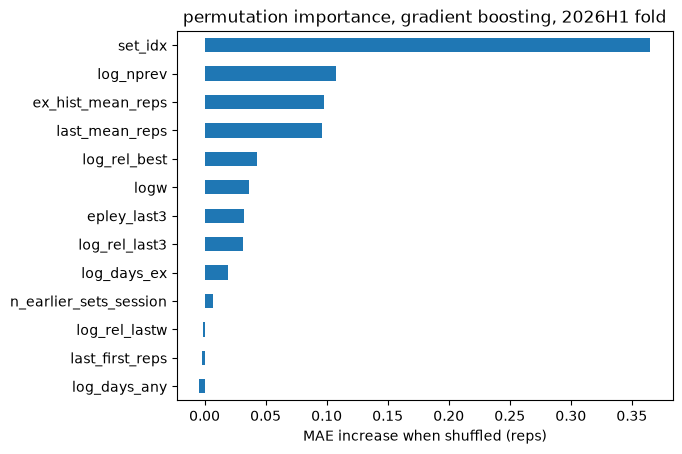

set_idx                   0.365
log_nprev                 0.108
ex_hist_mean_reps         0.098
last_mean_reps            0.096
log_rel_best              0.043
logw                      0.037
epley_last3               0.033
log_rel_last3             0.031
log_days_ex               0.019
n_earlier_sets_session    0.007
log_rel_lastw            -0.001
last_first_reps          -0.002
log_days_any             -0.004
dtype: float64


In [16]:
fold, train_idx, test_idx = ROLLING_FOLDS[-1]
model = models()['hgb'].fit(model_rows.iloc[train_idx][FEATS], model_rows.reps.iloc[train_idx])
importance = permutation_importance(model, model_rows.iloc[test_idx][FEATS], model_rows.reps.iloc[test_idx],
                                    scoring='neg_mean_absolute_error', n_repeats=10, random_state=SEED)
imp = pd.Series(importance.importances_mean, index=FEATS).sort_values()
imp.plot.barh()
plt.xlabel('MAE increase when shuffled (reps)')
plt.title('permutation importance, gradient boosting, 2026H1 fold')
plt.show()
print(imp.sort_values(ascending=False).round(3))

Shuffling the set position raises the error far more than any other feature, so the drop in reps across sets at the same weight is what the model uses most. The next features are the number of earlier sessions on the lift and my usual and recent rep levels, while strength features such as the ratio to my best 1RM matter much less. The session count partly stands in for time, which is one way the model can follow a level that moves. These values come from one fold, the newest one, so they show what the model relied on there and not a fixed ranking.

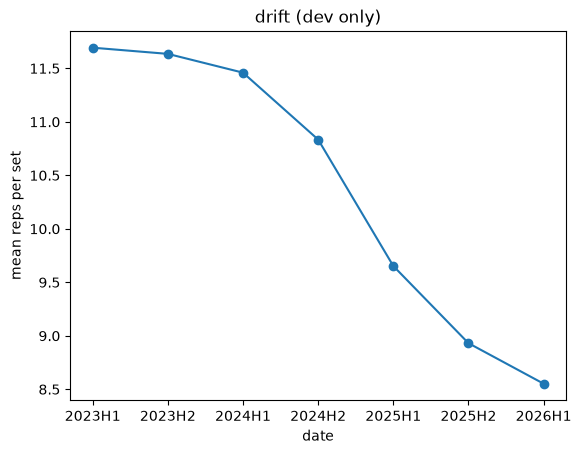

         mean  size
date               
2023H1  11.69  1437
2023H2  11.64   757
2024H1  11.46   892
2024H2  10.83   603
2025H1   9.65   538
2025H2   8.93   681
2026H1   8.55   880


In [17]:
MIN_SETS_PER_HALF = 50   # dev ends 2026-07-01, so "2026H2" would be a single day
no_drops = dev[dev.set_type != 'drop']
half_year = no_drops.date.dt.year.astype(str) + 'H' + np.where(no_drops.date.dt.month > 6, '2', '1')
half = no_drops.groupby(half_year).reps.agg(['mean', 'size'])
half = half[half['size'] >= MIN_SETS_PER_HALF]
half['mean'].plot(marker='o')
plt.ylabel('mean reps per set')
plt.title('drift (dev only)')
plt.show()
print(half.round(2))

To see whether my rep level changed, I average the reps per set in each half-year of the development data. My mean reps per set fell from 11.69 in 2023H1 to 8.55 in 2026H1. A model trained on earlier years expects more reps than I now do, which is consistent with the mean residual of gradient boosting in the rolling folds above, which moves from +0.28 in the first window to -1.21 in 2025H2.

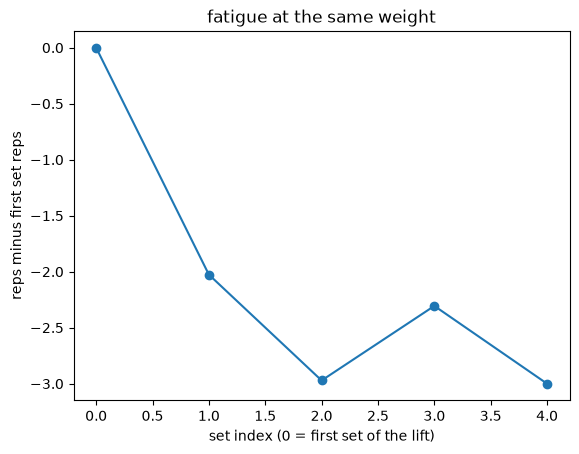

              n  drop_vs_set0
set_idx                      
0        2023.0          0.00
1        1483.0         -2.03
2         870.0         -2.97
3          36.0         -2.31
4           2.0         -3.00


In [18]:
MAX_SET_IDX_SHOWN = 4   # 5+ sets of one lift at one weight almost never happen
working_sets = feats[feats.is_drop == 0].copy()
working_sets['first_weight'] = working_sets.groupby(['session_id', 'exercise']).weight_lb.transform('first')
working_sets['first_reps'] = working_sets.groupby(['session_id', 'exercise']).reps.transform('first')
same_weight = working_sets[(working_sets.weight_lb == working_sets.first_weight) & (working_sets.set_idx <= MAX_SET_IDX_SHOWN)]
fatigue = same_weight.groupby('set_idx').apply(
    lambda sets_at_idx: pd.Series({'n': len(sets_at_idx), 'drop_vs_set0': (sets_at_idx.reps - sets_at_idx.first_reps).mean()}))
plt.plot(fatigue.index, fatigue.drop_vs_set0, marker='o')
plt.xlabel('set index (0 = first set of the lift)')
plt.ylabel('reps minus first set reps')
plt.title('fatigue at the same weight')
plt.show()
print(fatigue.round(2))

This plot shows the drop in reps across sets at the same weight that the yardstick at the start of this section uses, and it is the pattern behind the high importance of the set position. Fourth and fifth sets at the same weight are too rare for a reliable estimate.

In [19]:
# noise floor: consecutive sets, same lift, same session, same weight
ordered = feats[feats.is_drop == 0].sort_values(['sess_num', 'row_id'])
by_lift_session = ordered.groupby(['session_id', 'exercise'])
pair = pd.DataFrame({'rep_change': ordered.reps - by_lift_session.reps.shift(1),
                     'same_weight': ordered.weight_lb == by_lift_session.weight_lb.shift(1)}).dropna()
pair = pair[pair.same_weight]
rep_change = pair.rep_change
noise_mae = (rep_change - rep_change.mean()).abs().mean()
print('pairs', len(pair), '| mean change %.2f | sd %.2f' % (rep_change.mean(), rep_change.std()))
print('noise floor MAE (mean shift removed) %.3f | implied per-set sd %.3f' % (noise_mae, rep_change.std() / np.sqrt(2)))

pairs 2733 | mean change -1.63 | sd 2.00
noise floor MAE (mean shift removed) 1.559 | implied per-set sd 1.411


To judge how close the models come, I compare them with two sets that should be the same. Among 2,733 pairs of consecutive sets at the same weight, the reps change by -1.63 on average with a standard deviation of 2.0. After I remove that average drop, predicting a set from the one before it leaves an error of 1.56 reps. The best time-forward MAE, 1.876 for the random forest, is about 0.3 reps above this floor.

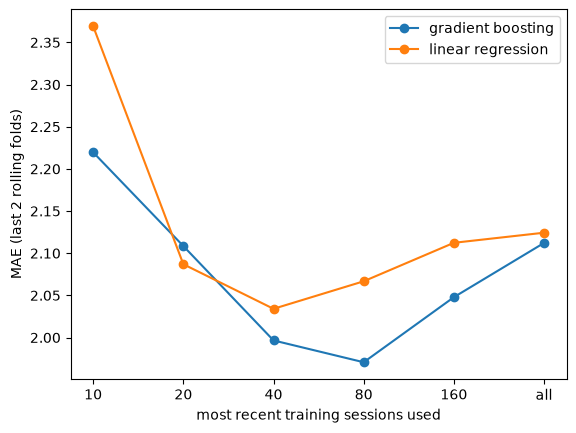

model       linreg    hgb
n_sessions               
10           2.369  2.220
20           2.087  2.108
40           2.034  1.997
80           2.067  1.971
160          2.112  2.048
all          2.124  2.112
all = every earlier session: [244, 289] sessions in the two folds


In [20]:
learning_curve = []
for fold, train_idx, test_idx in ROLLING_FOLDS[-2:]:   # the two newest folds
    train_sessions = model_rows.iloc[train_idx].sort_values('sess_ts').session_id.unique()
    for n in [10, 20, 40, 80, 160, len(train_sessions)]:
        keep = model_rows.iloc[train_idx].session_id.isin(train_sessions[-n:]).values
        recent_idx = train_idx[keep]
        for name in ['linreg', 'hgb']:
            model = models()[name].fit(model_rows.iloc[recent_idx][FEATS], model_rows.reps.iloc[recent_idx])
            pred = clip_reps(model.predict(model_rows.iloc[test_idx][FEATS]))
            learning_curve.append({'fold': fold, 'n_sessions': n if n < len(train_sessions) else 'all', 'model': name,
                                   'MAE': np.abs(pred - model_rows.reps.iloc[test_idx]).mean()})
learning_curve = pd.DataFrame(learning_curve)
learning_curve_mean = learning_curve.groupby(['n_sessions', 'model'], sort=False).MAE.mean().unstack()
plt.plot(range(len(learning_curve_mean)), learning_curve_mean['hgb'], marker='o', label=NICE_NAMES['hgb'])
plt.plot(range(len(learning_curve_mean)), learning_curve_mean['linreg'], marker='o', label=NICE_NAMES['linreg'])
plt.xticks(range(len(learning_curve_mean)), learning_curve_mean.index)
plt.legend()
plt.xlabel('most recent training sessions used')
plt.ylabel('MAE (last 2 rolling folds)')
plt.show()
print(learning_curve_mean.round(3))
print('all = every earlier session:', [model_rows.iloc[train_idx].session_id.nunique() for _, train_idx, _ in ROLLING_FOLDS[-2:]], 'sessions in the two folds')

If drift is the problem, recent sessions should matter more than old ones, so in the two newest folds I also train on only the most recent sessions. The figure above is the learning curve of this study, because it plots the error against the number of most recent training sessions, and it shows that the error stops falling at about 40 to 80 sessions. Training on the 40 to 80 most recent sessions is as good as or better than training on all 244 to 289. For gradient boosting the MAE is 1.971 with the 80 most recent sessions and 2.112 with all of them. More history does not help.

## Final Test Set

In the code the final test set is called the holdout. Its cell runs only when `FINAL=1` is set, after the cleaning rules and models are frozen.

I froze every cleaning rule and model before I used the final test set, and nothing was tuned on it.

In [21]:
# FINAL HOLDOUT RUN, after the pipeline is frozen. Run with FINAL=1 in the environment
if os.environ.get('FINAL') != '1':
    print('holdout locked')
else:
    all_feats = build_features(read_clean_sets())
    all_feats = all_feats[all_feats.has_hist == 1]
    train, test = all_feats[all_feats.date < HOLDOUT_START], all_feats[all_feats.date >= HOLDOUT_START]
    holdout_preds = test[['row_id', 'session_id', 'reps']].copy()
    holdout_preds['repeat_last'] = clip_reps(test.last_mean_reps)
    holdout_preds['inv_epley'] = clip_reps(test.epley_last3.fillna(test.last_mean_reps))
    for name, model in models().items():
        if isinstance(model, GridSearchCV):
            model.fit(train[FEATS], train.reps, groups=train.session_id)
        else:
            model.fit(train[FEATS], train.reps)
        holdout_preds[name] = clip_reps(model.predict(test[FEATS]))
    print('holdout rows', len(holdout_preds), 'sessions', holdout_preds.session_id.nunique())
    for name in MODELS:
        line = f"{name:12s} MAE {np.abs(holdout_preds[name] - holdout_preds.reps).mean():.3f}  within1 {within1(holdout_preds.reps.values, holdout_preds[name].values).mean():.3f}"
        if name not in ['const_mean', 'repeat_last']:
            line += '  vs const ' + fmt_ci(*boot(holdout_preds, name, 'const_mean'), 3)
            line += '  vs repeat ' + fmt_ci(*boot(holdout_preds, name, 'repeat_last'), 3)
        print(line)

holdout rows 374 sessions 37
const_mean   MAE 3.599  within1 0.238
repeat_last  MAE 1.605  within1 0.610
inv_epley    MAE 5.455  within1 0.233  vs const +1.857 [+1.113, +2.636]  vs repeat +3.850 [+3.161, +4.604]
linreg       MAE 1.710  within1 0.513  vs const -1.889 [-2.157, -1.649]  vs repeat +0.105 [-0.035, +0.252]
knn          MAE 1.782  within1 0.511  vs const -1.816 [-2.124, -1.535]  vs repeat +0.177 [-0.018, +0.375]
tree         MAE 1.828  within1 0.513  vs const -1.771 [-2.102, -1.445]  vs repeat +0.223 [+0.016, +0.430]
rf           MAE 1.629  within1 0.532  vs const -1.970 [-2.283, -1.682]  vs repeat +0.024 [-0.147, +0.192]
hgb          MAE 1.716  within1 0.532  vs const -1.883 [-2.198, -1.589]  vs repeat +0.111 [-0.064, +0.296]


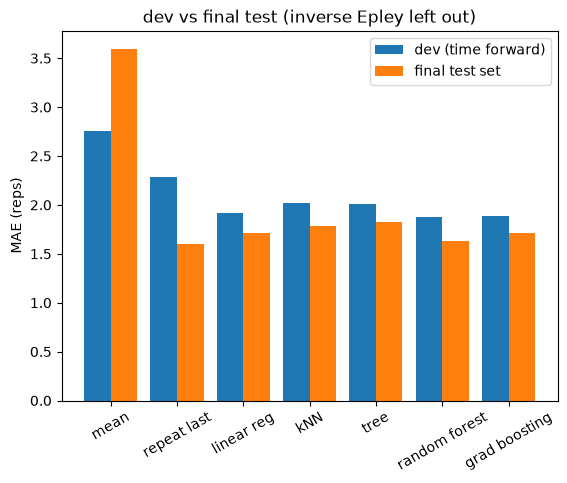

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

dev = pd.read_csv('data/results_dev.csv')
dev_mae = dev[dev.split == 'rolling (6 folds)'].set_index('model').MAE
# final test MAEs copied from the output above
final_mae = pd.Series({'const_mean': 3.599, 'repeat_last': 1.605, 'linreg': 1.710, 'knn': 1.782,
                       'tree': 1.828, 'rf': 1.629, 'hgb': 1.716})
names = {'const_mean': 'mean', 'repeat_last': 'repeat last', 'linreg': 'linear reg', 'knn': 'kNN',
         'tree': 'tree', 'rf': 'random forest', 'hgb': 'grad boosting'}
x = np.arange(len(final_mae))
plt.bar(x - 0.2, dev_mae[final_mae.index], width=0.4, label='dev (time forward)')
plt.bar(x + 0.2, final_mae, width=0.4, label='final test set')
plt.xticks(x, [names[m] for m in final_mae.index], rotation=30)
plt.ylabel('MAE (reps)')
plt.title('dev vs final test (inverse Epley left out)')
plt.legend()
plt.show()

## Final Test Set Results

The figure above shows the MAE of each model on the time forward development split next to the final test set. Inverse Epley is left out because its error of more than 5 reps would squash the other bars.

The final test set contains 374 sets from 37 sessions. Repeating the last session gives an MAE of 1.605, the random forest gives 1.629, linear regression 1.710, gradient boosting 1.716, kNN 1.782, the tree 1.828, the constant mean 3.599 and Epley 5.455. Compared with repeating the last session, the difference is +0.024 [-0.147, +0.192] for the random forest and +0.111 [-0.064, +0.296] for gradient boosting, so neither is better. The within-one rate favors the baseline, with 0.610 against 0.532 for the random forest and gradient boosting, although the notebook gives no interval for this difference. All models still beat the constant mean by about 1.8 to 2.0 reps.

## Discussion

On the development data the models beat both baselines with clear intervals. On the final test set they beat only the mean, and none of them beats repeating my last session.

My rep level kept changing, and this is the most likely reason why repeating my last session wins on the final test set. Its error fell from 2.288 on the development data to 1.605, while the models improved less and the mean got worse, as the figure in the results shows. So the final test reps lie further from the average of the training data than the development reps did. The repeat rule keeps no memory of older sessions, so it follows such a shift at once. The models learn from all 361 development sessions, and in the later development folds they already predicted too many reps. One hypothesis is that part of my older, higher rep level is still in their predictions. I have not tested this on the final test set, and the appendix check gives it little support, because training only on the 60 most recent sessions changed the development error by -0.016 [-0.046, +0.016], which includes zero. A second likely explanation, which I have also not tested, is that I made little progress in the last three months, so each session looked much like the one before it, and in that case repeating my last session is hard to beat. The final test set is also small, with 37 sessions, so part of the gap may be chance.

The models cannot get much closer to my sets, because the log does not record how hard a set was. I take most of my sets to failure, but the development data mark failure on only one set, and the RPE columns are empty. So a hard set and an easy set look the same to the model. The models mostly combine my recent rep level with the drop in reps across sets at the same weight, and repeating my last session already captures the first part. The best development model is about 0.3 reps above the floor of 1.56 reps for two sets that should be the same. Most of what remains is likely day-to-day variation that the log does not record.

One set of my own shows this limit directly. Before a normal workout on 17 October 2026, I asked the frozen models, trained on my cleaned sessions up to 8 October 2026, to predict my first set of machine curls at 110 lb, and the random forest predicted 9.17 reps, gradient boosting 9.40 and repeating my last session 7. I did 8 full reps and a partial ninth, as the [video of the set](https://github.com/Almasx/cs156/blob/main/first-assignment/demo/machine_curl_2026-10-17.mp4) shows, and the set stopped short of failure, yet my log would record it the same way as a set taken to failure. The [prediction sheet](https://github.com/Almasx/cs156/blob/main/first-assignment/demo/prediction_sheet.md) keeps this prediction with the time I made it, at about 7 pm Pacific time before I lifted. Because it is a single set, it shows how the tool is used and is not evidence of accuracy.

<a href="https://github.com/Almasx/cs156/blob/main/first-assignment/demo/machine_curl_2026-10-17.mp4">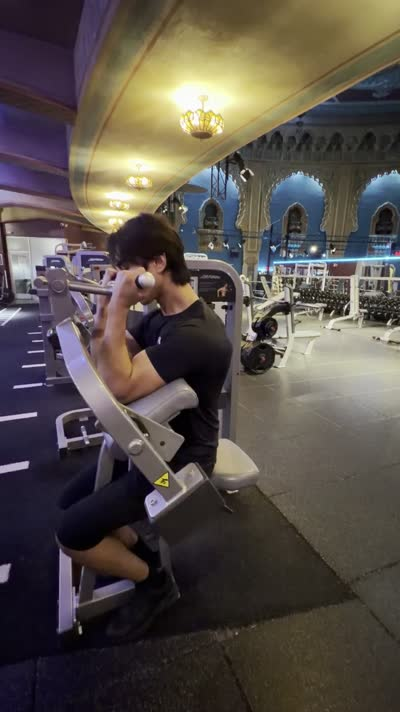</a>

Figure 9. My first set of machine curls at 110 lb on 17 October 2026, linked to the video.

Random and grouped splits flatter the flexible models, because my training changes with time. One likely route is the number of earlier sessions on the lift. It grows with time, so it lets a model tie each stretch of my training to its own rep level. In a random or grouped split, the model only has to fill in between sessions it has seen. In the rolling split, the counts for the lifts I train most go beyond any count seen in training. A tree based model predicts the same value for every count beyond its last split, so it cannot extend a falling level. Linear regression could extend a trend in the session count, which might explain why it loses the least, but I have not tested this.

The next steps follow from these limits. I would log RPE or reps in reserve, so that a model can tell how hard a set was. I would also try recency weighting, which gives recent sessions more weight than old ones without dropping the older history the way the 60-session check did. Two further ideas are a model of the rep drop across sets that pools information across lifts, and a model that predicts the weight I choose for the next session instead of the reps.

## Conclusion

Because no model did better than repeating my last session on the final test set, a prediction from my last session is off by about 1.6 reps on average, with an MAE of 1.605, and almost all of what the models can predict comes from my recent sessions. When I plan a workout, my last session on a lift is therefore a good guide to the reps I can expect, and a closer prediction would need a record of how hard each set was rather than more history.

## AI Statement

I used AI tools to help with formatting the paper and the PDF export, and with editing the wording. The data, analysis choices and results are my own.

## References
* Epley, B. (1985). *Poundage Chart.* Boyd Epley Workout. Lincoln, NE: Body Enterprises.
* Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *JMLR* 12, 2825-2830. User guide pages on nearest neighbors regression, decision trees, ensembles (RandomForestRegressor, HistGradientBoostingRegressor) and GroupKFold. https://scikit-learn.org/stable/user_guide.html
* Breiman, L. (2001). Random forests. *Machine Learning* 45, 5-32.
* Friedman, J. H. (2001). Greedy function approximation: a gradient boosting machine. *Annals of Statistics* 29(5), 1189-1232.
* Efron, B. & Tibshirani, R. (1993). *An Introduction to the Bootstrap.* Chapman & Hall.
* Hyndman, R. J. & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice*, 3rd ed., section on time series cross-validation. OTexts.

## Appendix

This appendix collects checks that support the main result but are not needed to follow it. All of them use development data only.

### Training on Recent Sessions Only

This check trains gradient boosting on only the 60 most recent sessions in each rolling fold, and the Discussion discusses its result.

In [23]:
# cheap fix for drift: only train on the most recent sessions
RECENT_SESSIONS = 60
recent_preds = []
for fold, train_idx, test_idx in ROLLING_FOLDS:
    recent_sessions = model_rows.iloc[train_idx].sort_values('sess_ts').session_id.unique()[-RECENT_SESSIONS:]
    recent_idx = train_idx[model_rows.iloc[train_idx].session_id.isin(recent_sessions).values]
    model = models()['hgb'].fit(model_rows.iloc[recent_idx][FEATS], model_rows.reps.iloc[recent_idx])
    pred = clip_reps(model.predict(model_rows.iloc[test_idx][FEATS]))
    recent_preds.append(pd.Series(pred, index=model_rows.row_id.iloc[test_idx].values))
recency_preds = rolling_preds.assign(hgb_last60=pd.concat(recent_preds).loc[rolling_preds.row_id].values)
err_all = np.abs(recency_preds.hgb - recency_preds.reps)
err_recent = np.abs(recency_preds.hgb_last60 - recency_preds.reps)
print('rolling MAE hgb all history %.3f, last 60 sessions %.3f' % (err_all.mean(), err_recent.mean()))
print('last60 - all:', np.round(boot(recency_preds, 'hgb_last60', 'hgb'), 3))
change_per_fold = []
for fold in sorted(recency_preds.fold.unique()):
    in_fold = recency_preds.fold == fold
    change_per_fold.append(float(round(err_recent[in_fold].mean() - err_all[in_fold].mean(), 3)))
print('per fold:', change_per_fold)

rolling MAE hgb all history 1.888, last 60 sessions 1.873
last60 - all: [-0.016 -0.046  0.016]
per fold: [-0.004, 0.017, 0.117, 0.066, -0.188, -0.042]


### Rows Without Convention Flags

In [24]:
# robustness 1: only rows with no convention flag (dumbbell pair/single, added-load pull-ups, kg checks)
clean_rows = model_rows[model_rows.flag_any == 0].reset_index(drop=True)
clean_preds = run(clean_rows, 'rolling (6 folds)', which=['const_mean', 'linreg', 'hgb'])
print('clean subset rows', len(clean_rows), 'of', len(model_rows))
for name in ['const_mean', 'repeat_last', 'linreg', 'hgb']:
    print(name, 'rolling MAE %.3f' % np.abs(clean_preds[name] - clean_preds.reps).mean())
print('hgb vs repeat_last', np.round(boot(clean_preds, 'hgb', 'repeat_last'), 3))

clean subset rows 4768 of 5756
const_mean rolling MAE 2.846
repeat_last rolling MAE 2.326
linreg rolling MAE 1.943
hgb rolling MAE 1.921
hgb vs repeat_last [-0.405 -0.471 -0.341]


I could not resolve some rows with certainty, so I checked whether they change the result. Without the flagged rows (dumbbell convention, added load pull-ups, unchecked kilogram values and corrected kilogram values), 4,768 of 5,756 rows remain. The rolling MAE is then 2.846 for the mean, 2.326 for the repeat of the last session, 1.943 for linear regression and 1.921 for gradient boosting. Gradient boosting still beats the repeat of the last session by -0.41 [-0.47, -0.34], so the flagged rows do not drive the result.

### Drop Set Flag

In [25]:
# robustness 2: drop-set flag ablation, only 2024-07 onward because the first app never marks drop sets
# assumption: I know before the set that it is a drop set (true, I plan them)
ABLATION_STARTS = ['2025-01-01', '2025-07-01', '2026-01-01']
since_2024h2 = model_rows[model_rows.date >= '2024-07-01'].reset_index(drop=True)
ablation = {}
for label, feature_cols in [('no drop flag', FEATS), ('with drop flag', FEATS + ['is_drop'])]:
    fold_preds = []
    for start in ABLATION_STARTS:
        start = pd.Timestamp(start)
        end = min(start + pd.DateOffset(months=FOLD_MONTHS), HOLDOUT_START)
        is_train = since_2024h2.date < start
        is_test = (since_2024h2.date >= start) & (since_2024h2.date < end)
        model = models()['hgb'].fit(since_2024h2.loc[is_train, feature_cols], since_2024h2.reps[is_train])
        pred = clip_reps(model.predict(since_2024h2.loc[is_test, feature_cols]))
        fold_preds.append(since_2024h2.loc[is_test, ['session_id', 'reps', 'is_drop']].assign(pred=pred))
    ablation[label] = pd.concat(fold_preds)
flag_preds = ablation['no drop flag'].rename(columns={'pred': 'no_flag'})
flag_preds['with_flag'] = ablation['with drop flag'].pred.values
err_no_flag = np.abs(flag_preds.no_flag - flag_preds.reps)
err_with_flag = np.abs(flag_preds.with_flag - flag_preds.reps)
print('rows', len(flag_preds), 'of which drop sets', int(flag_preds.is_drop.sum()))
print('hgb MAE no flag %.3f, with flag %.3f' % (err_no_flag.mean(), err_with_flag.mean()))
print('with - without', np.round(boot(flag_preds, 'with_flag', 'no_flag'), 3))
print('drop sets only: no flag %.3f, with flag %.3f' % (err_no_flag[flag_preds.is_drop == 1].mean(), err_with_flag[flag_preds.is_drop == 1].mean()))

rows 2243 of which drop sets 218
hgb MAE no flag 1.912, with flag 1.743
with - without [-0.169 -0.219 -0.116]
drop sets only: no flag 3.361, with flag 2.030


Drop sets are hard to predict when the model does not know that a set is one, so I tested a drop set flag. This test uses only data from 2024-07 onward, because the first app does not mark drop sets. The model assumes that the drop set flag is known before the set. The flag reduces the overall MAE from 1.912 to 1.743 (-0.17 [-0.22, -0.12]) and the MAE on drop sets alone from 3.36 to 2.03. However, drop sets are only about 10% of the rows (218 of 2,243), so the flag stays out of the headline model to keep all three years comparable.

### All Models and All Splits

This table has the same columns as the raw headline table and covers every model and every split.

In [26]:
# all models and all splits
table

,split,model,MAE,within1,MAE diff vs repeat_last [95% CI],within-1 diff vs repeat_last [95% CI],MAE diff vs const_mean [95% CI],within-1 diff vs const_mean [95% CI]
0,random 80/20,const_mean,2.546,0.427,"+0.35 [+0.22, +0.49]","-0.011 [-0.048, +0.025]",-,-
1,random 80/20,repeat_last,2.199,0.438,-,-,"-0.35 [-0.49, -0.22]","+0.011 [-0.025, +0.048]"
2,random 80/20,inv_epley,5.221,0.229,"+3.02 [+2.69, +3.40]","-0.209 [-0.247, -0.171]","+2.68 [+2.32, +3.07]","-0.198 [-0.237, -0.157]"
3,random 80/20,linreg,1.807,0.517,"-0.39 [-0.48, -0.31]","+0.079 [+0.046, +0.111]","-0.74 [-0.86, -0.62]","+0.090 [+0.056, +0.129]"
4,random 80/20,knn,1.741,0.548,"-0.46 [-0.54, -0.37]","+0.109 [+0.077, +0.140]","-0.80 [-0.92, -0.69]","+0.121 [+0.087, +0.154]"
5,random 80/20,tree,1.889,0.518,"-0.31 [-0.40, -0.22]","+0.080 [+0.051, +0.110]","-0.66 [-0.77, -0.54]","+0.091 [+0.056, +0.126]"
6,random 80/20,rf,1.673,0.574,"-0.53 [-0.62, -0.44]","+0.135 [+0.103, +0.168]","-0.87 [-0.99, -0.76]","+0.147 [+0.109, +0.184]"
7,random 80/20,hgb,1.689,0.553,"-0.51 [-0.60, -0.42]","+0.115 [+0.083, +0.146]","-0.86 [-0.98, -0.74]","+0.126 [+0.090, +0.163]"
8,group5 (session),const_mean,2.533,0.413,"+0.31 [+0.23, +0.38]","-0.018 [-0.035, +0.000]",-,-
9,group5 (session),repeat_last,2.224,0.431,-,-,"-0.31 [-0.38, -0.23]","+0.018 [-0.000, +0.035]"
